# Radar Equation

``` {important} Objectives
:class: dropdown
- Understand the monostatic radar equation
- Explain the physical meaning of each parameter
- Calculate received power as a function of range
- Visualize the $R^{-4}$ dependence
- Investigate parameter sensitivity
- Estimate detection range using receiver sensitivity
```

## 1. Radar Fundamentals
A radar transmits electromagnetic energy toward a target. A portion of the scattered energy returns to the radar receiver. The received power is governed by the radar equation.

### Monostatic Radar Equation

$$P_r = \dfrac{P_t G^2 \lambda^2 \sigma}{(4\pi)^3 R^4 L}$$

where:
- $P_t$ = transmitted power
- $G$ = antenna gain
- $\lambda$ = wavelength
- $\sigma$ = radar cross section (RCS)
- $R$ = range
- $L$ = system losses

The most important observation is that received power decreases as $R^{-4}$.

In [9]:
import numpy as np
import matplotlib.pyplot as plt


## 2. Define Radar Parameters

In [2]:
Pt = 1e6      # W
G_dB = 35     # dB
f = 10e9      # Hz
sigma = 1.0   # m^2
L_dB = 3      # dB

c = 3e8
lam = c/f
G = 10**(G_dB/10)
L = 10**(L_dB/10)

print(f"Wavelength = {lam:.4f} m")

Wavelength = 0.0300 m


## 3. Received Power versus Distance

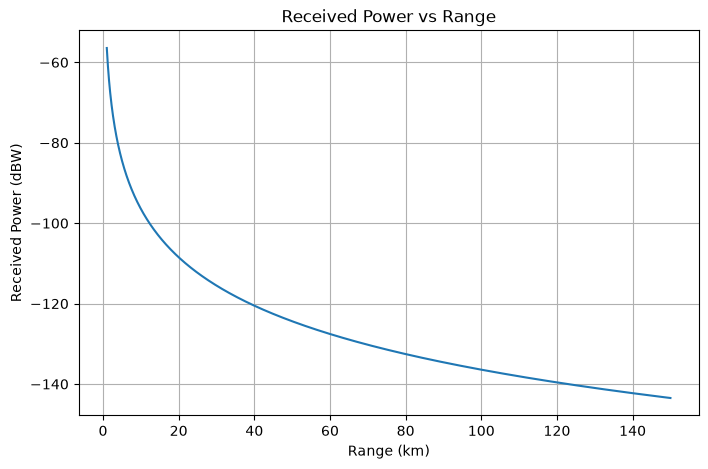

In [ ]:
R = np.linspace(1e3,150e3,2000)
Pr = (Pt*G**2*lam**2*sigma)/(((4*np.pi)**3)*(R**4)*L)
Pr_dBW = 10*np.log10(Pr)

plt.figure(figsize=(8,5))
plt.plot(R/1000,Pr_dBW)
plt.xlabel('Range (km)')
plt.ylabel('Received Power (dBW)')
plt.title('Received Power vs Range')
plt.grid(True)
plt.show()

## 4. Log-Log Representation

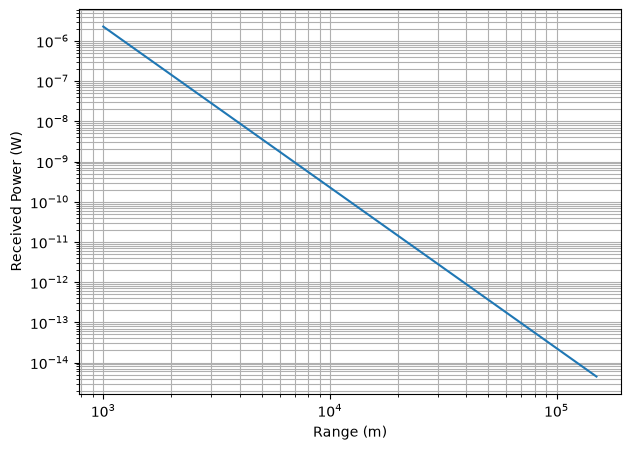

In [4]:
plt.figure(figsize=(7,5))
plt.loglog(R,Pr)
plt.xlabel('Range (m)')
plt.ylabel('Received Power (W)')
plt.grid(True,which='both')
plt.show()

## 5. Example Values at Selected Ranges

In [5]:
for r_km in [5,10,25,50,100,150]:
    r=r_km*1000
    pr=(Pt*G**2*lam**2*sigma)/(((4*np.pi)**3)*(r**4)*L)
    print(f'{r_km:>3} km : {10*np.log10(pr):8.2f} dBW')

  5 km :   -84.39 dBW
 10 km :   -96.43 dBW
 25 km :  -112.35 dBW
 50 km :  -124.39 dBW
100 km :  -136.43 dBW
150 km :  -143.48 dBW


## 6. Sensitivity to Radar Cross Section

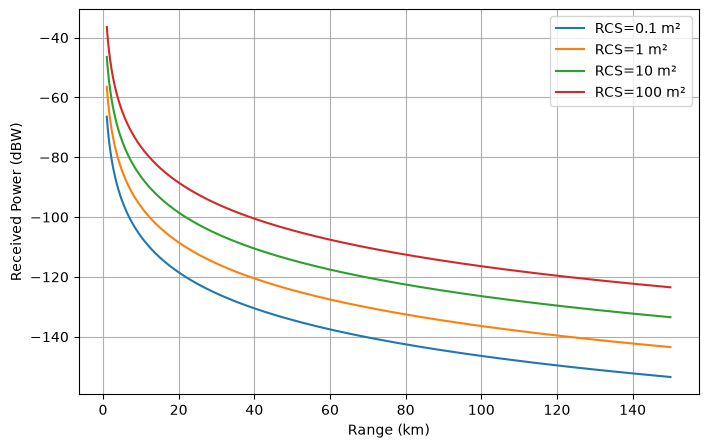

In [6]:
rcs_values=[0.1,1,10,100]
plt.figure(figsize=(8,5))
for s in rcs_values:
    pr=(Pt*G**2*lam**2*s)/(((4*np.pi)**3)*(R**4)*L)
    plt.plot(R/1000,10*np.log10(pr),label=f'RCS={s} m²')
plt.xlabel('Range (km)')
plt.ylabel('Received Power (dBW)')
plt.legend()
plt.grid(True)
plt.show()

## 7. Sensitivity to Antenna Gain

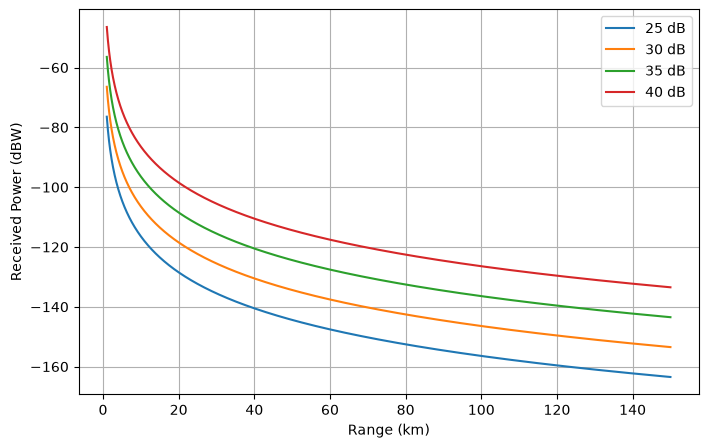

In [7]:
plt.figure(figsize=(8,5))
for gain_db in [25,30,35,40]:
    Gx=10**(gain_db/10)
    pr=(Pt*Gx**2*lam**2*sigma)/(((4*np.pi)**3)*(R**4)*L)
    plt.plot(R/1000,10*np.log10(pr),label=f'{gain_db} dB')
plt.xlabel('Range (km)')
plt.ylabel('Received Power (dBW)')
plt.legend()
plt.grid(True)
plt.show()

## 8. Detection Range Estimation
Assume receiver sensitivity of -120 dBW. Determine the maximum detectable range.

In [8]:
threshold_dBW=-120
threshold=10**(threshold_dBW/10)
Rmax=((Pt*G**2*lam**2*sigma)/(((4*np.pi)**3)*L*threshold))**0.25
print(f'Maximum detection range = {Rmax/1000:.2f} km')

Maximum detection range = 38.83 km


```{exercise} Exercises
:class: dropdown

1. Derive the radar equation from power density arguments.
2. Explain why range appears with the fourth power.
3. Compare X-band and S-band systems.
4. Add thermal noise and compute SNR.
5. Investigate coherent integration gain.
6. Model fluctuating targets using different RCS values.
7. Determine required transmit power for a desired detection range.
```

```{exercise}  10. Mini Project
:class: dropdown

Create a tool that accepts radar parameters and automatically computes:
- Received power
- Detection range
- SNR
- Plots versus distance
- Comparison of multiple target classes
```